# Telco customer churn: analysis walkthrough

**Question:** which customers are about to leave, why, and is it worth spending money to keep them?

This notebook explains the reasoning. The reusable code lives in `src/`; run `python run_pipeline.py` to reproduce everything.

1. Data and cleaning  2. Exploratory analysis  3. Modelling  4. Evaluation  5. Explainability  6. Business value  7. Limitations

In [1]:
import sys, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")
import joblib, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
from src import config, data_prep, eda, evaluate, business, train
raw = data_prep.load_raw(config.RAW_FILE)
raw.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 1. Data and cleaning
One row per customer; `Churn` is the outcome. Two things to check before anything else: duplicates and the text column `TotalCharges`.

In [2]:
print(raw.shape, "| duplicate ids:", raw.customerID.duplicated().sum())
blank = pd.to_numeric(raw.TotalCharges, errors="coerce").isna()
print("Blank TotalCharges rows:", blank.sum(), "| their tenure values:", raw.loc[blank, "tenure"].unique())

(7043, 21) | duplicate ids: 0
Blank TotalCharges rows: 11 | their tenure values: [0]


All 11 blank rows have `tenure == 0`: brand-new customers who have not been billed yet. The honest value is **0**, not the average, so `clean()` sets 0 and raises an error if a blank ever appears for a customer with tenure above 0.

In [3]:
df = data_prep.prepare()
print(df.shape, "churn rate: %.1f%%" % (100 * df[config.TARGET].mean()))
df[["tenure", "MonthlyCharges", "TotalCharges", "n_addons", "avg_monthly_charge", "price_change", "autopay"]].describe(include="all").T.head(8)

(7043, 25) churn rate: 26.5%


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
MonthlyCharges,7043.0,NaN,NaN,NaN,64.761692,30.090047,18.25,35.5,70.35,89.85,118.75
TotalCharges,7043.0,NaN,NaN,NaN,2279.734304,2266.79447,0.0,398.55,1394.55,3786.6,8684.8
n_addons,7043.0,NaN,NaN,NaN,2.03791,1.847682,0.0,0.0,2.0,3.0,6.0
avg_monthly_charge,7043.0,NaN,NaN,NaN,64.762906,30.189796,13.775,35.935156,70.3375,90.174158,121.4
price_change,7043.0,NaN,NaN,NaN,-0.001213,2.614121,-18.9,-1.159091,0.0,1.145567,19.125
autopay,7043,2,No,3977,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2. Exploratory analysis
Churn is **26.5%** overall, so a model that always predicts staying is 73.5% accurate and useless. That is why we use ROC-AUC and PR-AUC instead of accuracy.

In [4]:
eda.categorical_association(df).head(8)

,feature,cramers_v,p_value,highest_churn_group,highest_rate,lowest_churn_group,lowest_rate
0,Contract,0.410,5.863038e-258,Month-to-month,0.427,Two year,0.028
1,OnlineSecurity,0.347,2.661150e-185,No,0.418,No internet service,0.074
2,TechSupport,0.343,1.443084e-180,No,0.416,No internet service,0.074
3,InternetService,0.322,9.571788e-160,Fiber optic,0.419,No,0.074
4,PaymentMethod,0.303,3.682355e-140,Electronic check,0.453,Credit card (automatic),0.152
5,OnlineBackup,0.292,2.079759e-131,No,0.399,No internet service,0.074
6,DeviceProtection,0.282,5.505219e-122,No,0.391,No internet service,0.074
7,StreamingMovies,0.231,2.667757e-82,No,0.337,No internet service,0.074


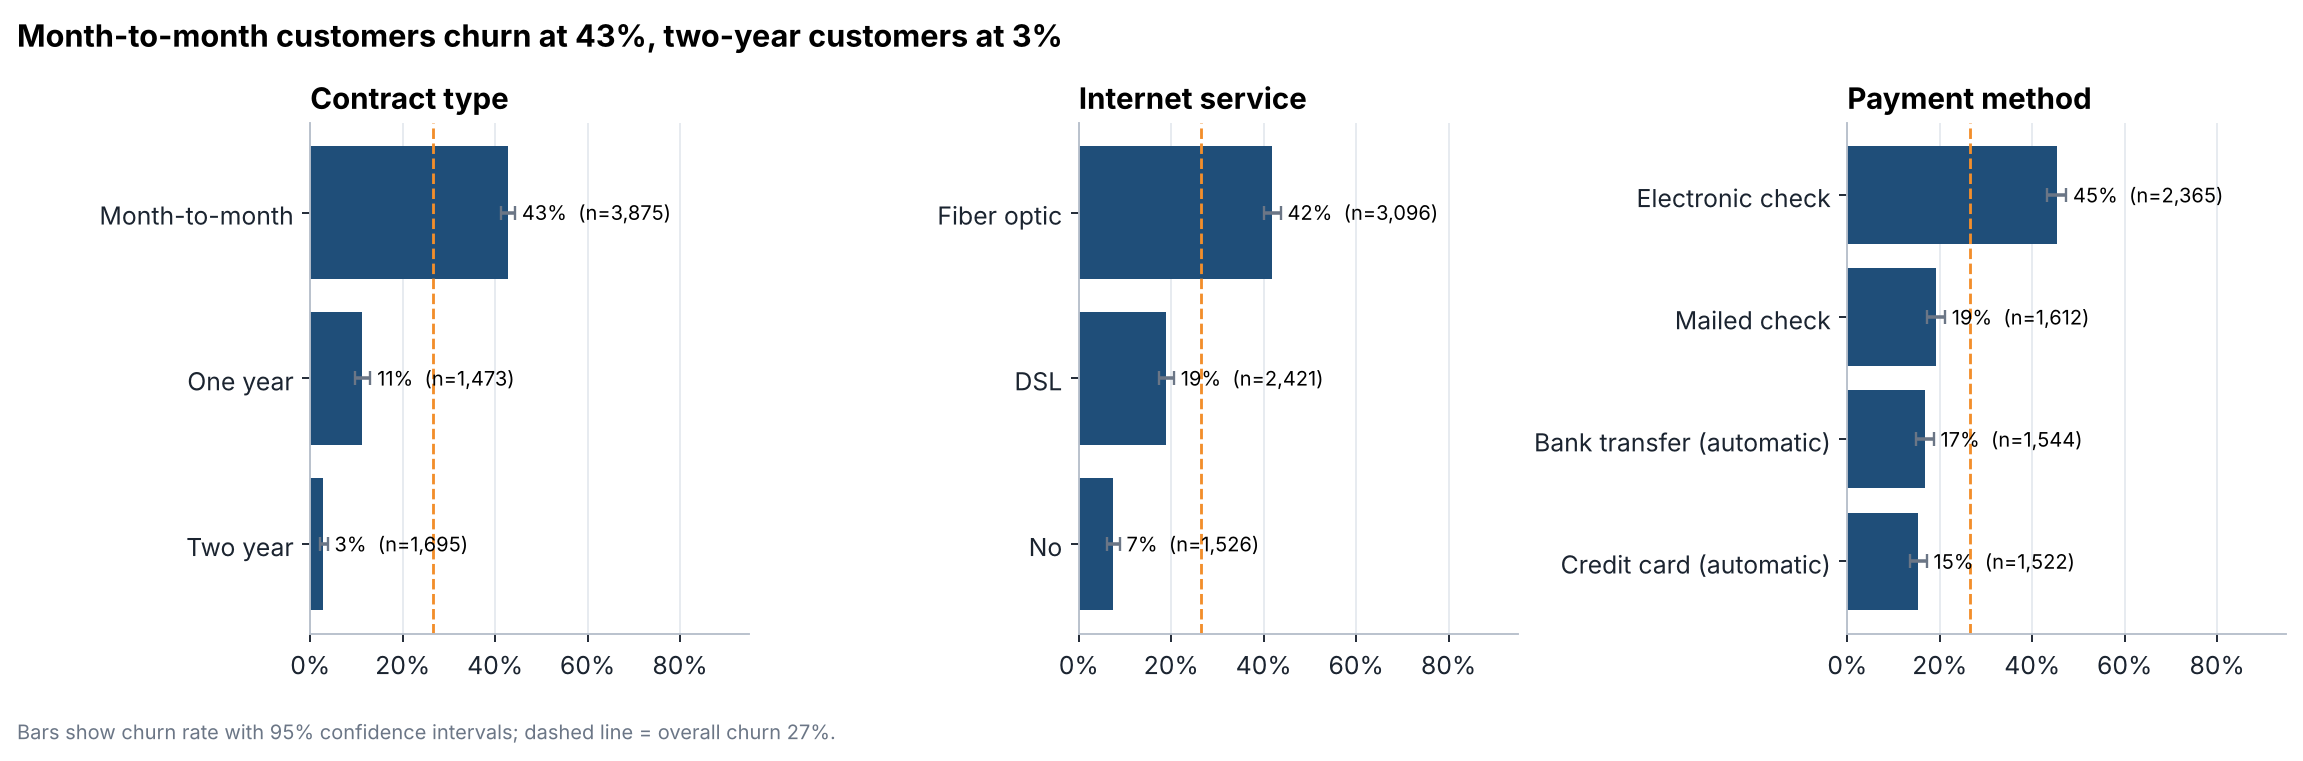

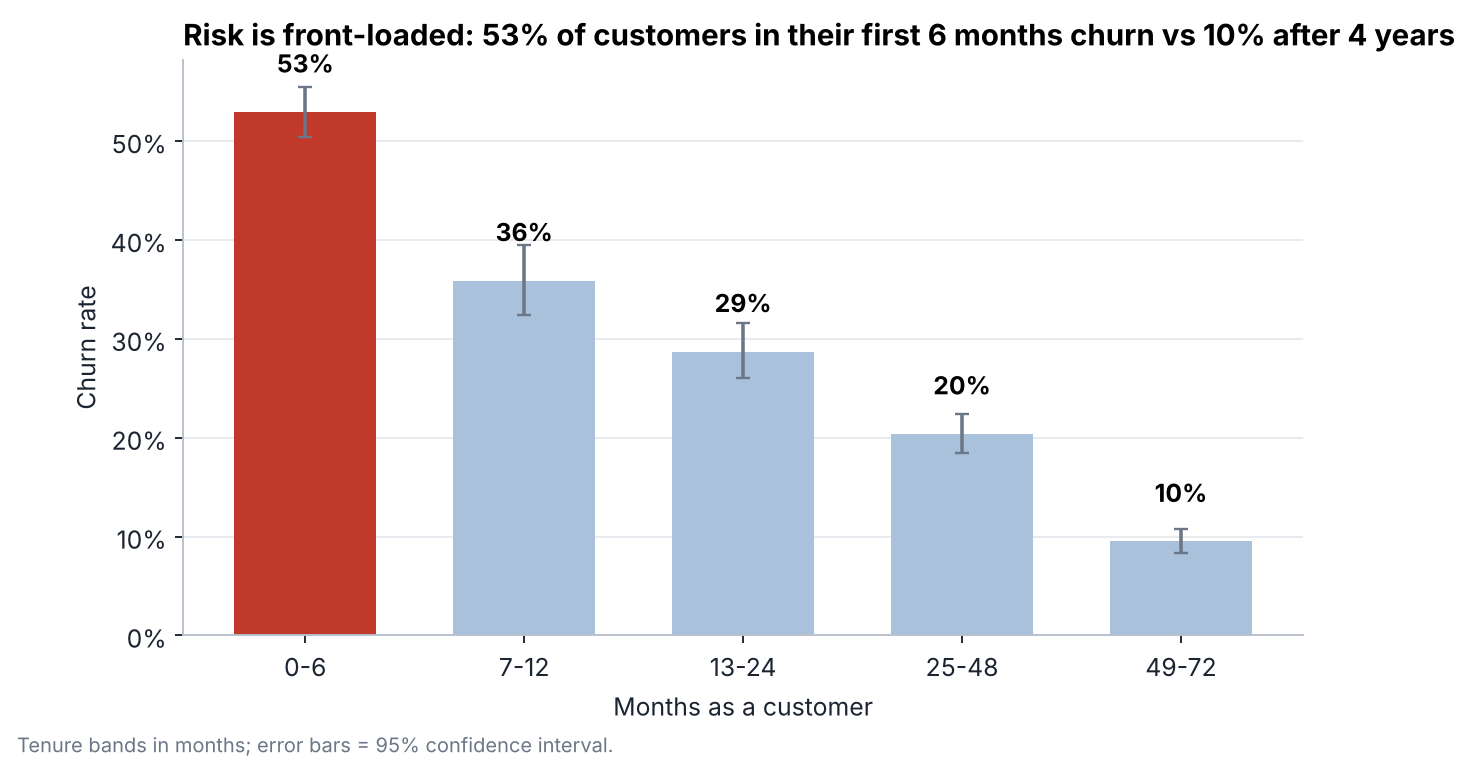

In [5]:
display(Image("../reports/figures/01_churn_by_segment.png"))
display(Image("../reports/figures/02_churn_by_tenure.png"))

Contract type, tenure and fibre internet dominate. The numeric tests confirm churners pay more per month and have much shorter tenure.

In [6]:
eda.numeric_tests(df)

,feature,median_churned,median_stayed,rank_biserial,p_value
0,tenure,10.0,38.0,-0.480,2.419636e-208
1,MonthlyCharges,79.7,64.4,0.242,3.311628e-54
2,TotalCharges,703.5,1679.5,-0.301,5.685034e-83


## 3. Modelling
A fair comparison needs a baseline and a protocol that never lets the test set influence a choice. Here is the minimal version (no tuning) before the full tuned run in `src/train.py`.

In [7]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from src.features import build_preprocessor
X_tr, X_te, y_tr, y_te = train.split(df)
cv = StratifiedKFold(5, shuffle=True, random_state=config.RANDOM_STATE)
for name, m in [("Logistic regression", LogisticRegression(max_iter=2000)),
                ("XGBoost (defaults)", XGBClassifier(eval_metric="logloss", n_jobs=1, random_state=42))]:
    s = cross_val_score(Pipeline([("prep", build_preprocessor()), ("model", m)]), X_tr, y_tr, cv=cv, scoring="roc_auc")
    print(f"{name:<22} CV ROC-AUC {s.mean():.3f} +/- {s.std():.3f}")

Logistic regression    CV ROC-AUC 0.846 +/- 0.013


XGBoost (defaults)     CV ROC-AUC 0.819 +/- 0.006


A plain logistic regression is already within about 0.01 AUC of tuned boosting. **That is a real finding:** the signal is mostly simple (contract, tenure, services), so a simple model is a legitimate choice if explainability matters more than the last percent. The pipeline still tunes all candidates and picks by cross-validation only.

In [8]:
meta = json.loads(config.META_FILE.read_text())
pd.DataFrame(meta["comparison"]).drop(columns="best_params")

,model,cv_roc_auc,test_roc_auc,test_pr_auc,test_brier,seconds
0,Baseline (predict base rate),0.5000,0.5000,0.2654,0.1950,0.1
1,Logistic regression,0.8460,0.8413,0.6272,0.1385,2.6
2,Random forest,0.8474,0.8436,0.6552,0.1360,24.6
3,XGBoost,0.8498,0.8456,0.6633,0.1355,14.1


## 4. Evaluation on the untouched test set

{'threshold': 0.22, 'roc_auc': 0.8456, 'pr_auc': 0.6633, 'brier': 0.1355, 'accuracy': 0.7175, 'precision': 0.4814, 'recall': 0.8316, 'f1': 0.6098}


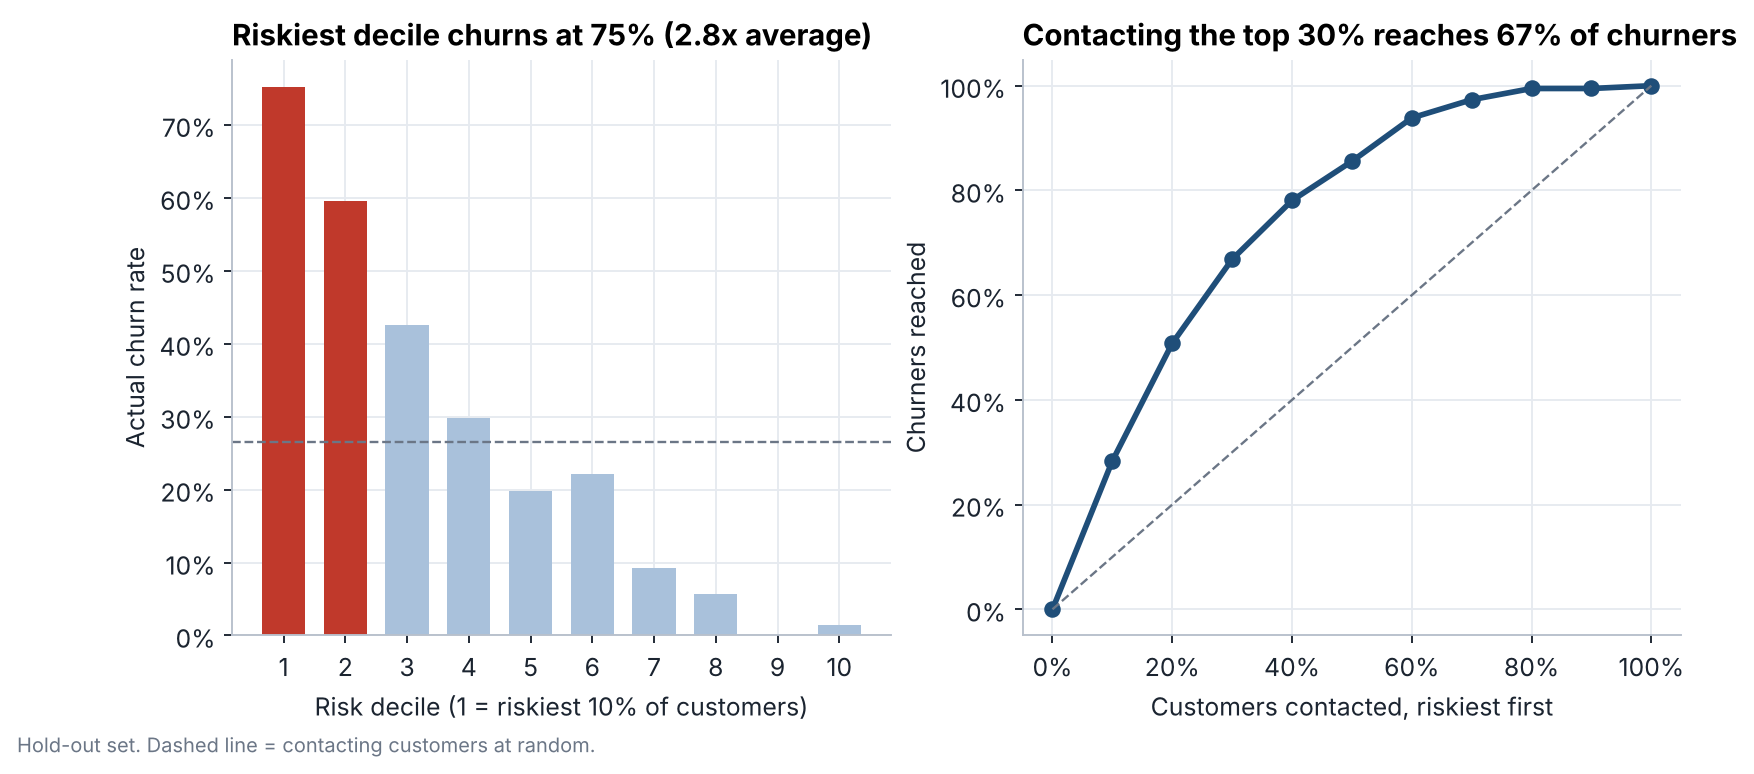

In [9]:
model = joblib.load(config.MODEL_FILE)
p = model.predict_proba(X_te)[:, 1]
m = evaluate.metrics_at(y_te, p, meta["operating_threshold"])
print({k: v for k, v in m.items() if k != "confusion"})
display(Image("../reports/figures/09_lift_gain.png"))

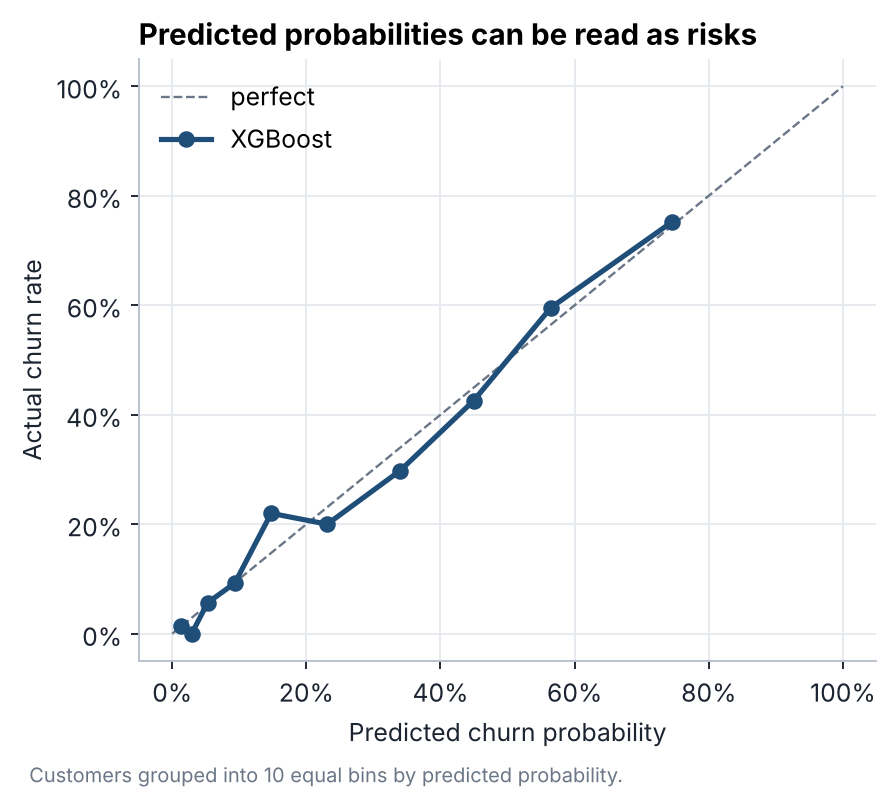

In [10]:
display(Image("../reports/figures/08_calibration.png"))

The probabilities are close to the diagonal, so a prediction of 40% really means roughly 4 in 10 such customers leave. That matters because the business calculation below multiplies these probabilities by money.

## 5. Explainability

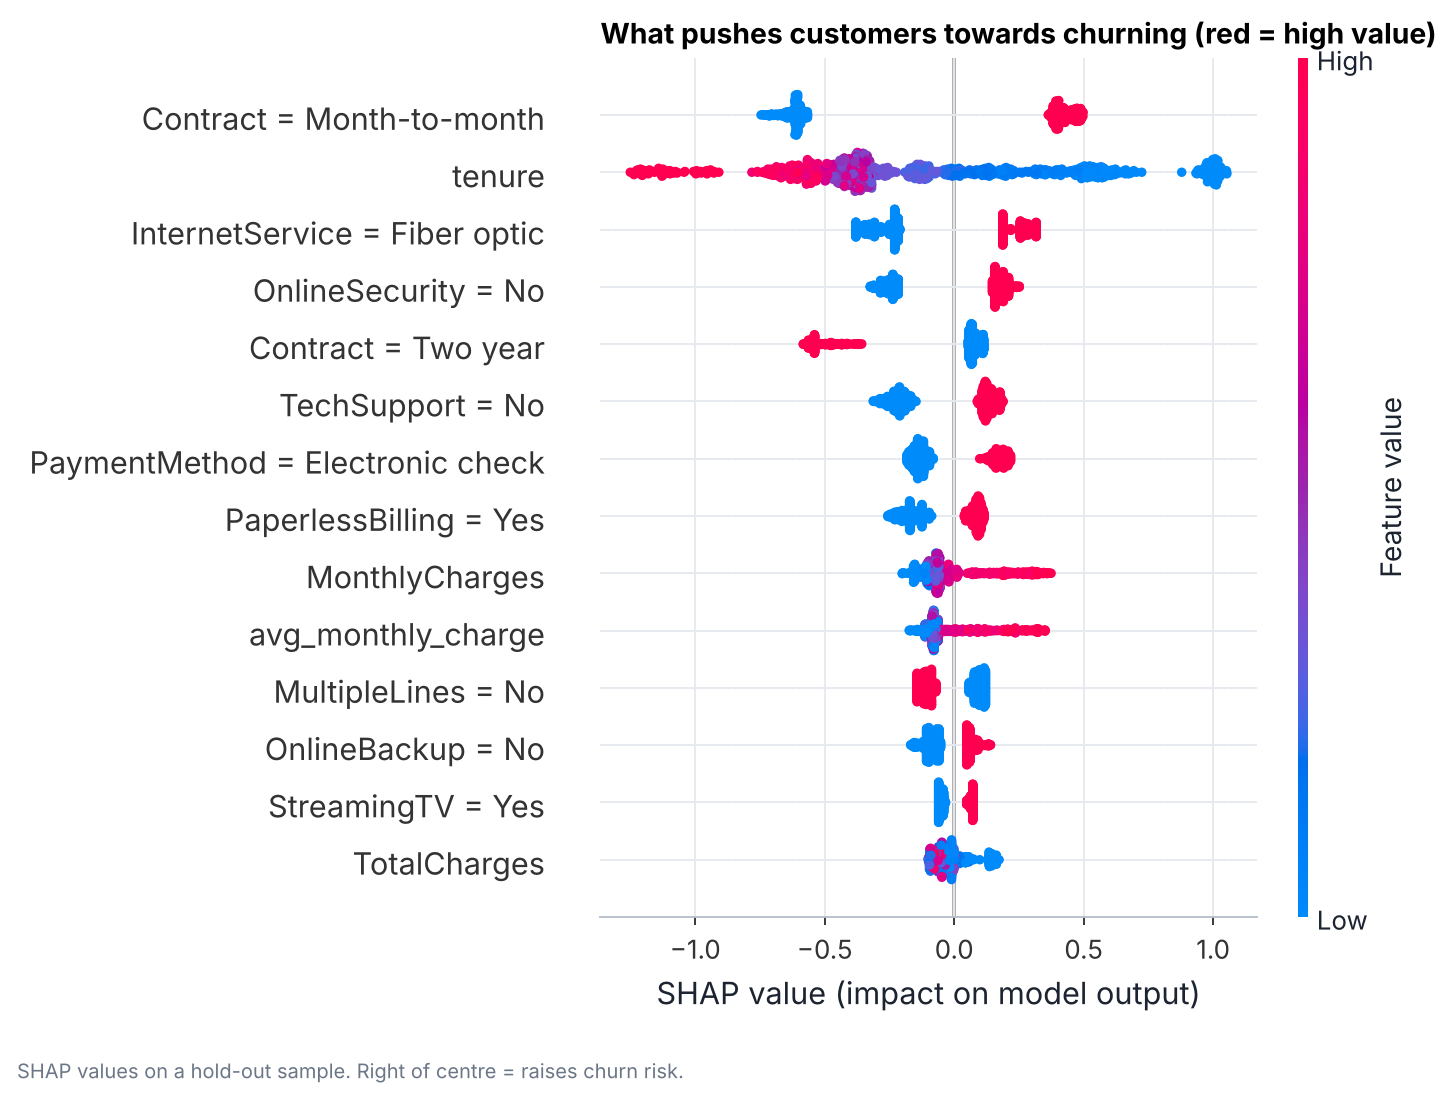

In [11]:
display(Image("../reports/figures/12_shap_summary.png"))

Month-to-month contracts, short tenure, fibre internet, no online security or tech support and electronic-check payment push risk **up**. These are associations in observational data, not proven causes.

## 6. From prediction to decision
A churn probability is not an action. The value of contacting a customer is `P(churn) x save rate x customer value - cost`. The margin, cost and save rate are **assumptions** (not in the data); the app lets you change them.

In [12]:
a = business.Assumptions()
scored = pd.read_csv(config.SCORED_FILE)
test_scored = scored[scored.split == "test"]
business.strategy_comparison(test_scored, a)

,strategy,customers_contacted,net_profit
0,Do nothing,0,0.000000
1,Contact everyone,1409,6716.820000
2,Contact a random group of the same size,577,2750.606913
3,Contact top by churn probability (same size),577,22213.590000
4,Model: contact only where expected benefit > 0,577,23447.220000


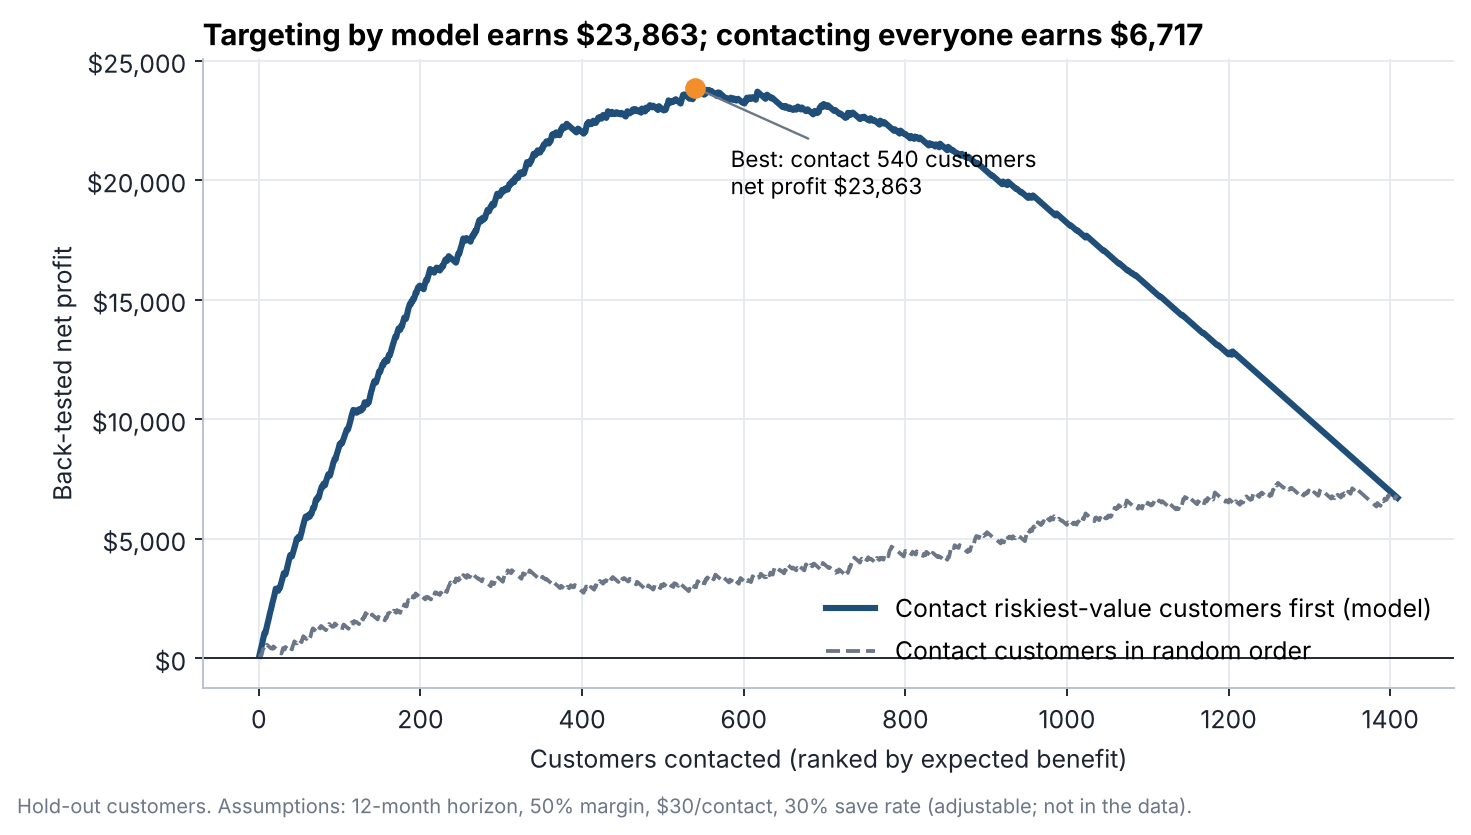

In [13]:
display(Image("../reports/figures/13_campaign_profit.png"))

## 7. Limitations and next steps
* One snapshot of one telecom sample: no time dimension, so we predict *who is at risk*, not *when*.
* The model finds who will leave, not who can be **persuaded** to stay. An **uplift model** or an **A/B test** is the right next step, and it is how the 30% save rate should be measured.
* `gender` is excluded on purpose; group metrics (`reports/fairness_check.csv`) should be monitored before any real use.
* Next project step: a time-based split and survival analysis (time to churn).